# 02 · Forecasting Weekly Demand

**Goal:** forecast next weeks' **regular demand** for each of the 5 products and, just as importantly, measure **how wrong those forecasts are**.
The size of the forecast error determines how much **safety stock** the retailer needs (notebook 03).

**Approach**
- Forecast **demand per trading day**, then multiply by the number of trading days in the target week (known in advance from the calendar).
  This way a bank-holiday week isn't mistaken for weak demand.
- **Rolling-origin back-test:** for every week, forecast using **only the weeks before it**, exactly as a planner would in real life.
- Three periods:

| Weeks | Period | Used for |
|---|---|---|
| 1–20 | Warm-up | Models need some history to start |
| 21–40 | **Validation** | Choosing the model and its settings, and measuring the errors that size the safety stock |
| 41–52 | **Test** (mid-Sep to early Dec) | Final, untouched check; never used for any decision |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import Ridge

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)

weekly = pd.read_csv("../data/weekly_demand.csv", parse_dates=["Week"])
PRODUCTS = ["Cakestand", "T-Light Holder", "Party Bunting", "Jumbo Bag", "Bird Ornament"]

demand = weekly.pivot(index="Week", columns="Product", values="Regular")[PRODUCTS]
tdays = weekly.pivot(index="Week", columns="Product", values="TradingDays")["Cakestand"].rename("TradingDays")
rate = demand.div(tdays.replace(0, np.nan), axis=0)       # demand per trading day; NaN in the closed week
WEEKS = demand.index
VAL = range(20, 40)     # weeks 21–40 (0-based positions)
TEST = range(40, 52)    # weeks 41–52
print(f"Validation: {WEEKS[20]:%d %b} – {WEEKS[39]:%d %b %Y}   |   Test: {WEEKS[40]:%d %b} – {WEEKS[51] + pd.Timedelta(days=6):%d %b %Y}")

Validation: 25 Apr – 05 Sep 2011   |   Test: 12 Sep – 04 Dec 2011


## 1. Error metrics

| Metric | Meaning |
|---|---|
| **WAPE** (weighted absolute % error) | Total absolute error ÷ total demand. "On average the forecast is off by X% of demand." Works well when weekly demand varies a lot |
| **Bias** | Total (forecast − actual) ÷ total demand. Negative = forecasts too **low** (risk of stock-outs); positive = too **high** (excess stock) |

In [2]:
def wape(d):
    return (d["Forecast"] - d["Actual"]).abs().sum() / d["Actual"].sum()

def bias(d):
    return (d["Forecast"] - d["Actual"]).sum() / d["Actual"].sum()

## 2. The candidate models

| Model | Idea |
|---|---|
| **Naive** | Next week = last week. The baseline every model must beat |
| **Moving average (4 or 8 weeks)** | Average of the last *k* weeks; smooths out noise |
| **Simple exponential smoothing (SES)** | Weighted average where recent weeks count more; the weight α (0–1) controls how fast it reacts |
| **Holt (damped trend)** | Exponential smoothing plus a trend that fades out over time |
| **Ridge regression** | One model pooled across all products, using recent lags as features |

Each function receives **only the history before the forecast week**.

In [3]:
def f_naive(h):          return h.iloc[-1]
def f_ma(h, k):          return h.iloc[-k:].mean()

def f_ses(h, alpha):
    level = h.iloc[0]
    for v in h.iloc[1:]:
        level = alpha * v + (1 - alpha) * level
    return level

def f_holt(h):
    m = ExponentialSmoothing(h.values, trend="add", damped_trend=True, initialization_method="estimated").fit()
    return max(m.forecast(1)[0], 0)

def backtest(method, weeks_range, horizon=1, **kw):
    # Forecast week i+horizon-1 using data up to (not including) week i
    rows = []
    for i in weeks_range:
        target = i + horizon - 1
        if target >= len(WEEKS) or tdays.iloc[target] == 0:
            continue
        for p in PRODUCTS:
            hist = rate[p].iloc[:i].dropna()          # only the past; closed week skipped
            r = method(hist, **kw)
            rows.append({"Origin": WEEKS[i], "Week": WEEKS[target], "Horizon": horizon, "Product": p,
                         "Forecast": r * tdays.iloc[target], "Actual": demand[p].iloc[target]})
    return pd.DataFrame(rows)

### Ridge regression (pooled across products)

With only ~40 weeks per product, a separate machine-learning model per product would overfit. We pool all 5 products into one model,
predicting log demand-per-day from the last 3 weeks, the 4- and 8-week averages, and a product indicator.

In [4]:
log_rate = np.log1p(rate)
feat_rows = []
for p in PRODUCTS:
    for i in range(8, len(WEEKS)):
        if tdays.iloc[i] == 0:
            continue
        h = log_rate[p].iloc[:i].dropna()
        feat_rows.append({"i": i, "Product": p, "y": log_rate[p].iloc[i], "lag1": h.iloc[-1], "lag2": h.iloc[-2],
                          "lag3": h.iloc[-3], "ma4": h.iloc[-4:].mean(), "ma8": h.iloc[-8:].mean()})
FEAT = pd.DataFrame(feat_rows)
FEAT = pd.concat([FEAT, pd.get_dummies(FEAT["Product"], prefix="p", dtype=float)], axis=1)
XCOLS = [c for c in FEAT.columns if c not in ("i", "Product", "y")]

def backtest_ridge(weeks_range):
    rows = []
    for i in weeks_range:
        if tdays.iloc[i] == 0:
            continue
        train, now = FEAT[FEAT["i"] < i], FEAT[FEAT["i"] == i]
        pred = np.expm1(Ridge(alpha=1.0).fit(train[XCOLS], train["y"]).predict(now[XCOLS]))
        for p, r in zip(now["Product"], pred):
            rows.append({"Origin": WEEKS[i], "Week": WEEKS[i], "Horizon": 1, "Product": p,
                         "Forecast": r * tdays.iloc[i], "Actual": demand[p].iloc[i]})
    return pd.DataFrame(rows)

## 3. Choose the smoothing weight α on the validation weeks

In [5]:
alphas = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
alpha_scores = pd.Series({a: wape(backtest(f_ses, VAL, alpha=a)) for a in alphas}, name="Validation WAPE")
BEST_ALPHA = alpha_scores.idxmin()
print(f"Best alpha = {BEST_ALPHA}")
alpha_scores.to_frame().T

Best alpha = 0.4


,0.100,0.200,0.300,0.400,0.500,0.600
Validation WAPE,0.338,0.325,0.324,0.322,0.323,0.330


The error is almost flat for α between 0.2 and 0.6, so the exact choice barely matters. α ≈ 0.4 means the latest week gets 40% of the weight.

## 4. Compare all models (one week ahead)

In [6]:
candidates = {
    "Naive (last week)":        lambda r: backtest(f_naive, r),
    "Moving average, 4 weeks":  lambda r: backtest(f_ma, r, k=4),
    "Moving average, 8 weeks":  lambda r: backtest(f_ma, r, k=8),
    f"Exp. smoothing (α={BEST_ALPHA})": lambda r: backtest(f_ses, r, alpha=BEST_ALPHA),
    "Holt, damped trend":       lambda r: backtest(f_holt, r),
    "Ridge regression (pooled)": backtest_ridge,
}
results, test_fc = [], {}
for name, run in candidates.items():
    v, t = run(VAL), run(TEST)
    test_fc[name] = t
    results.append({"Model": name, "Validation WAPE": wape(v), "Test WAPE": wape(t), "Test bias": bias(t)})
results = pd.DataFrame(results).set_index("Model")
results

,Validation WAPE,Test WAPE,Test bias
Model,,,
Naive (last week),0.384,0.365,-0.021
"Moving average, 4 weeks",0.331,0.313,-0.042
"Moving average, 8 weeks",0.341,0.306,-0.038
Exp. smoothing (α=0.4),0.322,0.293,-0.037
"Holt, damped trend",0.351,0.303,-0.070
Ridge regression (pooled),0.329,0.320,-0.097


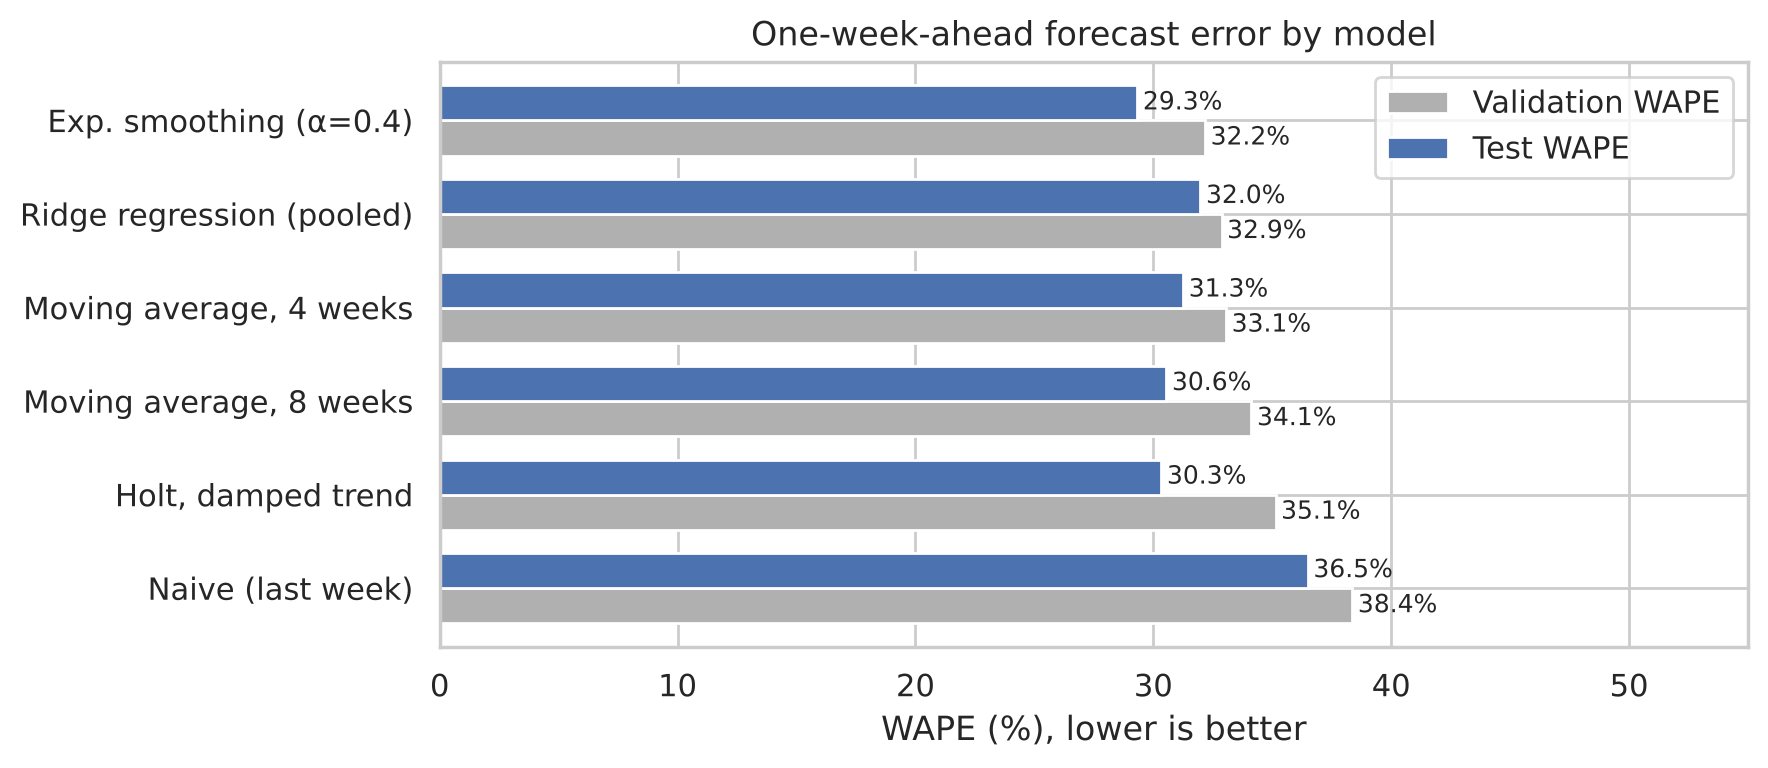

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = results[["Validation WAPE", "Test WAPE"]].mul(100).sort_values("Validation WAPE", ascending=False)
plot.plot.barh(ax=ax, color=["#B0B0B0", "#4C72B0"], width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
ax.set_xlabel("WAPE (%), lower is better"); ax.set_ylabel("")
ax.set_xlim(0, 55)
ax.set_title("One-week-ahead forecast error by model")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("../reports/figures/02_model_comparison.png", dpi=150)
plt.show()

### Decision: simple exponential smoothing

- It has the **lowest validation error**, so it's chosen *before* looking at the test set. It also performs best on the test set, which confirms the choice.
- **More complex models don't help.** Holt's trend and the ridge regression are no better: with 40 weeks of noisy data there's little extra pattern to learn.
- Exponential smoothing beats the naive "last week" forecast by **6–7 percentage points** of error (6.2 on validation, 7.2 on test).
- All models are slightly **biased low** in the test period (forecasting a bit under actual demand). That's typical in a season where demand is building up towards Christmas.

> A forecast error of ~30% sounds large, but it's normal for **weekly, single-product** demand. The point of notebook 03 is to make
> good ordering decisions *despite* that error, by measuring it and planning for it.

## 5. Test-period forecasts vs reality

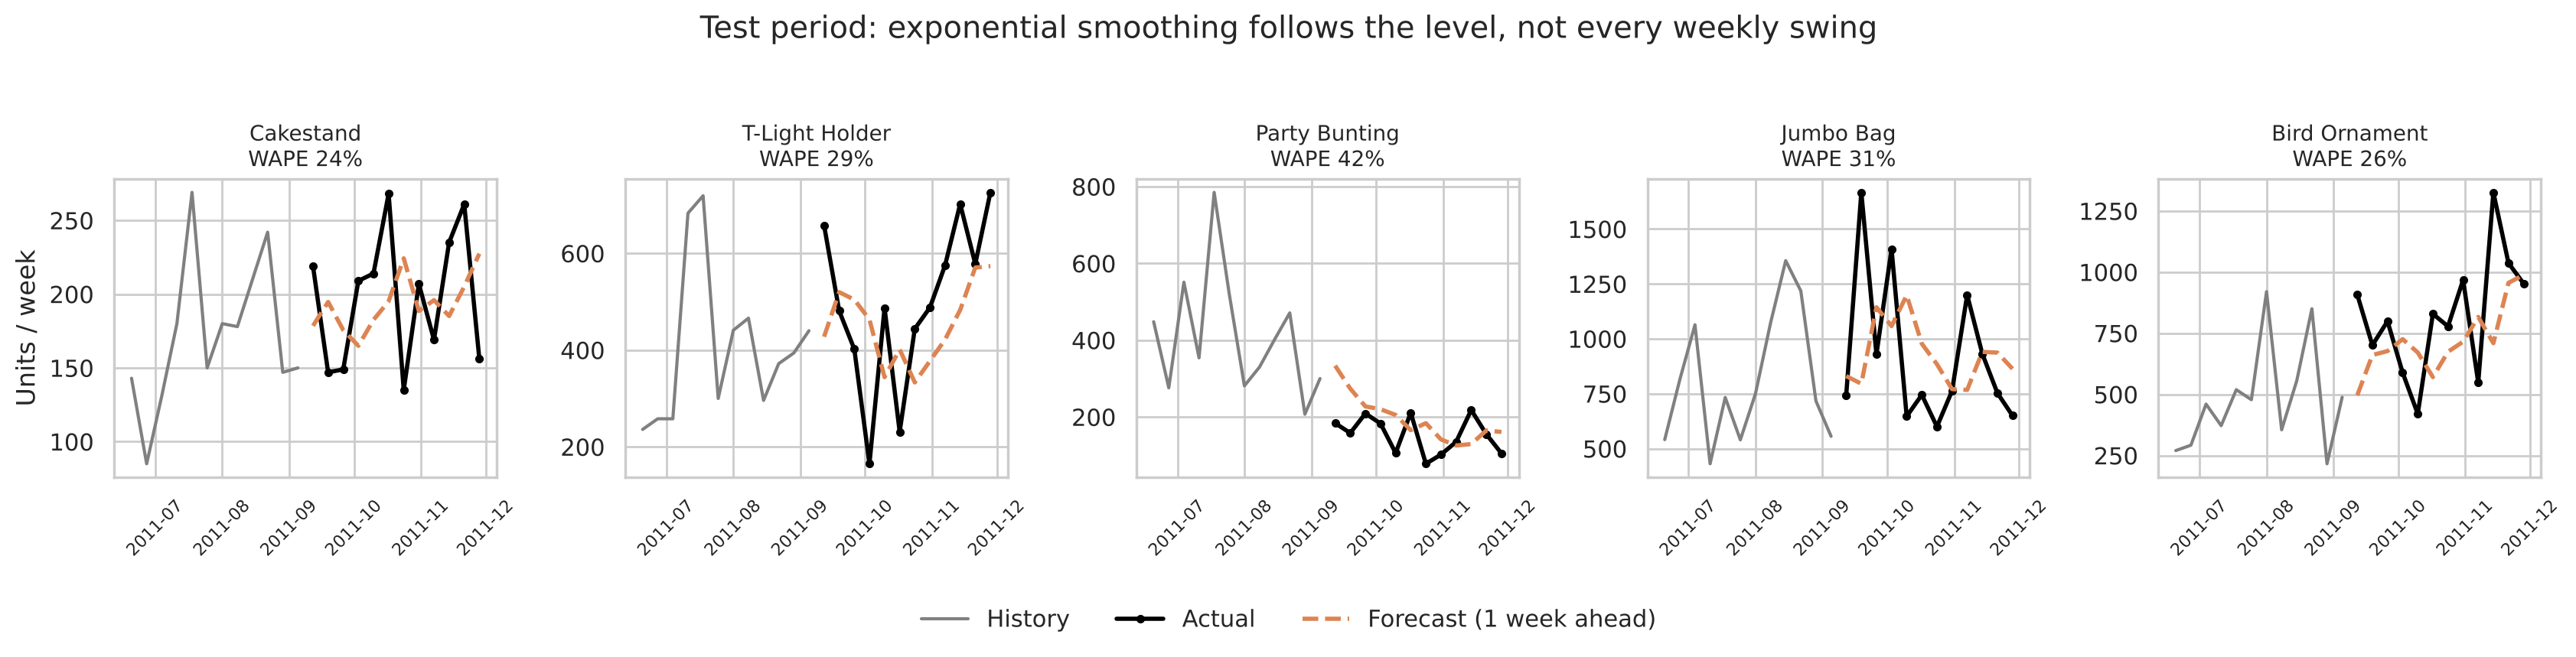

In [8]:
CHOSEN = f"Exp. smoothing (α={BEST_ALPHA})"
fc_test = test_fc[CHOSEN]
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharex=True)
for ax, p in zip(axes, PRODUCTS):
    hist = demand[p].iloc[28:40]
    d = fc_test[fc_test["Product"] == p]
    ax.plot(hist.index, hist.values, color="grey", lw=1.5, label="History")
    ax.plot(d["Week"], d["Actual"], color="black", lw=2, marker="o", ms=3, label="Actual")
    ax.plot(d["Week"], d["Forecast"], color="#DD8452", lw=2, ls="--", label="Forecast (1 week ahead)")
    ax.set_title(f"{p}\nWAPE {wape(d):.0%}", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0].set_ylabel("Units / week")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.suptitle("Test period: exponential smoothing follows the level, not every weekly swing", y=1.04)
plt.tight_layout()
plt.savefig("../reports/figures/02_test_forecasts.png", dpi=150, bbox_inches="tight")
plt.show()

Smoothing follows the **level** of demand but can't predict individual up-and-down swings, which are essentially random.
Party Bunting is the hardest: in autumn its demand is small and erratic, so the *percentage* error is largest.

## 6. How does the error grow with the forecast horizon?

The optimisation in notebook 03 plans orders **up to 4 weeks ahead**, so we need forecasts (and their errors) for horizons 1–4.
Simple exponential smoothing produces a **flat** forecast: the same value for every future week.

In [9]:
horizon_rows, all_val, all_test = [], [], []
for h in range(1, 5):
    v = backtest(f_ses, range(20, 40), horizon=h, alpha=BEST_ALPHA)
    t = backtest(f_ses, range(40, 52), horizon=h, alpha=BEST_ALPHA)
    all_val.append(v); all_test.append(t)
    horizon_rows.append({"Horizon (weeks ahead)": h, "Validation WAPE": wape(v), "Test WAPE": wape(t)})
horizon_tbl = pd.DataFrame(horizon_rows).set_index("Horizon (weeks ahead)")
horizon_tbl

,Validation WAPE,Test WAPE
Horizon (weeks ahead),,
1,0.322,0.293
2,0.359,0.314
3,0.358,0.337
4,0.372,0.317


The error grows only slowly with the horizon: weekly demand mostly fluctuates **around a slowly moving level**, so a 4-week-ahead
forecast is nearly as good as a 1-week-ahead one.

## 7. Measuring the uncertainty (for safety stock)

For each product we measure the **forecast error relative to the forecast** on the *validation* weeks:
$\text{relative error} = (\text{actual} - \text{forecast}) / \text{forecast}$.

Its standard deviation tells us how wide the uncertainty band is. Multiplied by a future forecast, it gives that week's uncertainty **in units**,
which is the input to safety stock.

In [10]:
val_h1 = all_val[0].copy()
val_h1["RelError"] = (val_h1["Actual"] - val_h1["Forecast"]) / val_h1["Forecast"]
test_h1 = all_test[0].copy()
test_h1["RelError"] = (test_h1["Actual"] - test_h1["Forecast"]) / test_h1["Forecast"]

unc = pd.DataFrame({
    "Rel. error std (validation)": val_h1.groupby("Product")["RelError"].std(),
    "Rel. error std (test, check)": test_h1.groupby("Product")["RelError"].std(),
    "Mean rel. error (validation)": val_h1.groupby("Product")["RelError"].mean(),
}).loc[PRODUCTS]
unc

,Rel. error std (validation),"Rel. error std (test, check)",Mean rel. error (validation)
Product,,,
Cakestand,0.290,0.268,-0.051
T-Light Holder,0.464,0.377,0.002
Party Bunting,0.336,0.363,-0.063
Jumbo Bag,0.422,0.441,0.040
Bird Ornament,0.452,0.402,-0.021


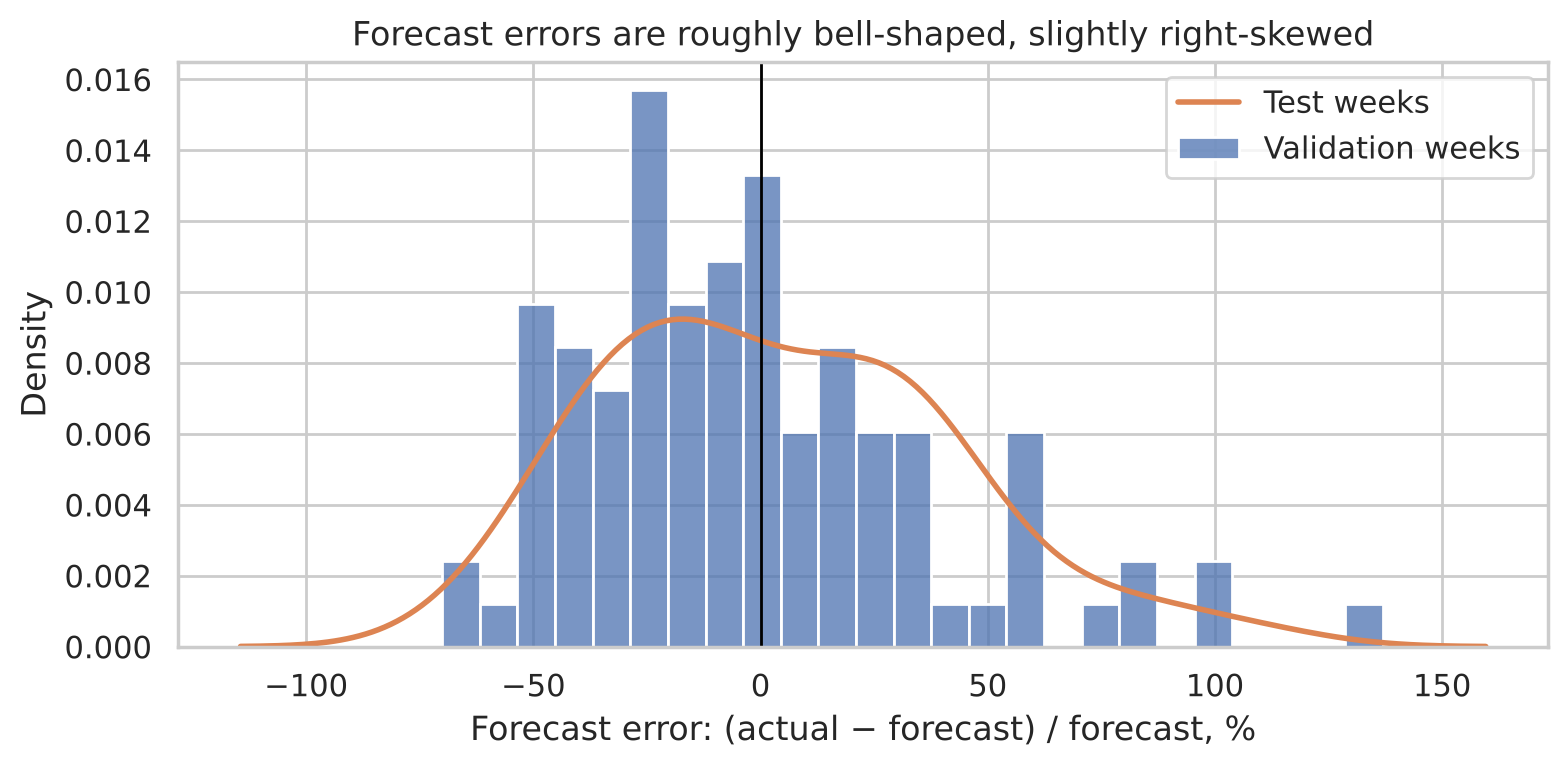

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(val_h1["RelError"] * 100, bins=25, color="#4C72B0", ax=ax, stat="density", label="Validation weeks")
sns.kdeplot(test_h1["RelError"] * 100, color="#DD8452", lw=2, ax=ax, label="Test weeks")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Forecast error: (actual − forecast) / forecast, %")
ax.set_title("Forecast errors are roughly bell-shaped, slightly right-skewed")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/02_error_distribution.png", dpi=150)
plt.show()

- The error spread measured on validation weeks is **similar to the test weeks** for most products, so it's a reasonable basis for setting safety stock.
- Errors are **slightly right-skewed**: demand occasionally jumps well above the forecast, which is exactly when stock-outs happen.

## 8. Save forecasts and uncertainty for the optimisation

In [12]:
pd.concat(all_val + all_test).to_csv("../data/forecasts.csv", index=False)
unc.rename(columns={"Rel. error std (validation)": "RelErrorStd"})[["RelErrorStd"]].to_csv("../data/forecast_uncertainty.csv")
print(f"Saved {len(pd.concat(all_val + all_test)):,} forecasts (horizons 1–4) and uncertainty for {len(PRODUCTS)} products")

Saved 610 forecasts (horizons 1–4) and uncertainty for 5 products


## Key takeaways

1. **Simple exponential smoothing** was the most accurate model on the validation weeks, and it held up on the untouched test weeks.
2. **Complex models (trend, ridge regression) were no better**; with 40 weeks of noisy data, simplicity wins again.
3. Exponential smoothing beats the naive "last week" forecast by **6–7 percentage points** of error.
4. Forecast error is **~30% of demand**, typical for weekly single-product demand, and grows only slightly up to 4 weeks ahead.
5. The error spread is measured per product and saved. It sets the **safety stock** in the next notebook.

**Next → `03_inventory_optimisation.ipynb`:** use the forecasts and their uncertainty in a **linear programme** that decides how much to order each week,
under warehouse and budget limits, and simulate it against a rule of thumb.